# Ngwerere (Zambia): de video a caudal con LSPIV

Mide el caudal del rio Ngwerere a partir de un video de una camara fija en la orilla, con
**LSPIV** (*Large-Scale Particle Image Velocimetry*) de la libreria **pyorc**. Reune en un solo
flujo los ejemplos `01` a `04` del repositorio de pyorc, con comentarios linea por linea.

Pasos:

1. Abrir el video y extraer un fotograma
2. Definir los puntos de control (GCPs) que ligan pixeles con coordenadas reales
3. Construir la configuracion de camara y reproyectar (ortorrectificar)
4. Calcular velocidades superficiales con LSPIV y filtrar las espurias
5. Muestrear un transecto batimetrico e integrar el caudal

Resultado esperado, el del ejemplo original (seccion transversal #1): mediana de 0.164 m3/s, con
P5 de 0.076 y P95 de 0.222 m3/s.

**Los datos de entrada se leen en modo solo lectura de `../../datos/ngwerere/`. Todo lo que este
notebook genera (JSON de camara, NetCDF de velocimetria, CSV de resultados y figuras PNG) se
escribe en `salidas/`, al lado del notebook.**

---
## Parte 0 - Rutas de trabajo

Todas las rutas son relativas a esta carpeta, que es desde donde se ejecuta el notebook.

In [1]:
from pathlib import Path

# --- Entradas (nunca se modifican) ---
DIR_DATOS = Path("../../datos/ngwerere")
ARCHIVO_VIDEO = DIR_DATOS / "ngwerere_20191103.mp4"             # video de 30 fps, 1920x1080
ARCHIVO_BATIMETRIA = DIR_DATOS / "ngwerere_cross_section.csv"   # transecto x, y, z en UTM 35S

# --- Salidas ---
DIR_SALIDA = Path("salidas")
# exist_ok=True evita el error si la carpeta ya existe de una ejecucion anterior.
DIR_SALIDA.mkdir(exist_ok=True)

SALIDA_CAM_CONFIG = DIR_SALIDA / "cam_config.json"         # configuracion de camara
SALIDA_PIV_CRUDO = DIR_SALIDA / "piv_crudo.nc"             # velocimetria sin filtrar
SALIDA_PIV_FILTRADO = DIR_SALIDA / "piv_filtrado.nc"       # velocimetria con mascaras
SALIDA_TRANSECTO = DIR_SALIDA / "transecto_caudal.nc"      # transecto con q y v_eff
SALIDA_RESUMEN = DIR_SALIDA / "caudal_resumen.csv"         # tabla final de caudales

print("Datos de entrada:", DIR_DATOS)
print("Salidas en:      ", DIR_SALIDA)
# Se comprueba de una vez que las entradas existen, antes de procesar nada. Si aparece FALTA,
# el notebook se lanzo desde otra carpeta.
for entrada in (ARCHIVO_VIDEO, ARCHIVO_BATIMETRIA):
    print(f"  {'OK   ' if entrada.exists() else 'FALTA'} {entrada.name}")

Datos de entrada: ..\..\datos\ngwerere
Salidas en:       salidas
  OK    ngwerere_20191103.mp4
  OK    ngwerere_cross_section.csv


---
## Parte 1 - Lectura del video

`pyorc.Video` envuelve el video y controla que rango de fotogramas se procesa. Aqui se lee un
solo fotograma en color para poder identificar visualmente los puntos de control.

Scanning video:   0%|          | 0/2 [00:00<?, ?it/s]

Scanning video:  50%|█████     | 1/2 [00:00<00:00,  6.77it/s]

Scanning video: 100%|██████████| 2/2 [00:00<00:00,  6.31it/s]

Dimensiones del fotograma: (1080, 1920, 3)
FPS del video: 30.0


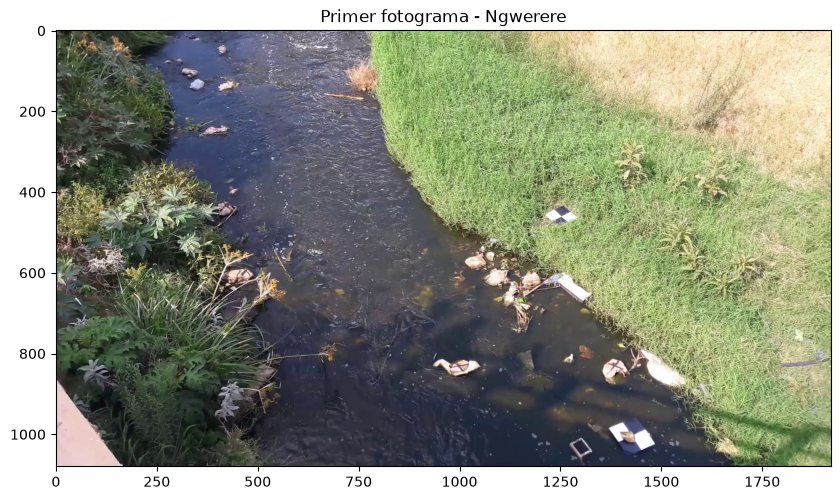

In [2]:
import matplotlib.pyplot as plt
import pyorc

# start_frame/end_frame limitan la lectura: para elegir los GCPs basta con un fotograma.
video = pyorc.Video(str(ARCHIVO_VIDEO), start_frame=0, end_frame=1)

# get_frame devuelve un array numpy. method="rgb" mantiene el color (por defecto seria gris,
# que es lo que usa el PIV, pero el color ayuda a ver los marcadores).
frame = video.get_frame(0, method="rgb")

# Forma (filas, columnas, canales): las filas son la altura y las columnas el ancho.
print(f"Dimensiones del fotograma: {frame.shape}")
print(f"FPS del video: {video.fps}")

plt.figure(figsize=(10, 6))
plt.imshow(frame)
plt.title("Primer fotograma - Ngwerere")
plt.savefig(DIR_SALIDA / "fig1_fotograma.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 2 - Puntos de control (GCPs)

Los GCPs ligan pixeles de la imagen con coordenadas del mundo real medidas con GPS RTK. Son lo
que permite convertir desplazamientos en pixeles a velocidades en metros por segundo.

- `src`: posiciones en la imagen, en pixeles, como `[columna, fila]`
- `dst`: las mismas posiciones en el mundo real, en el mismo orden, en UTM 35S (EPSG:32735)
- `z_0`: cota del nivel del agua durante el video, en la referencia vertical del RTK
- `h_ref`: lectura de la escala limnimetrica durante el video; con un solo video vale 0

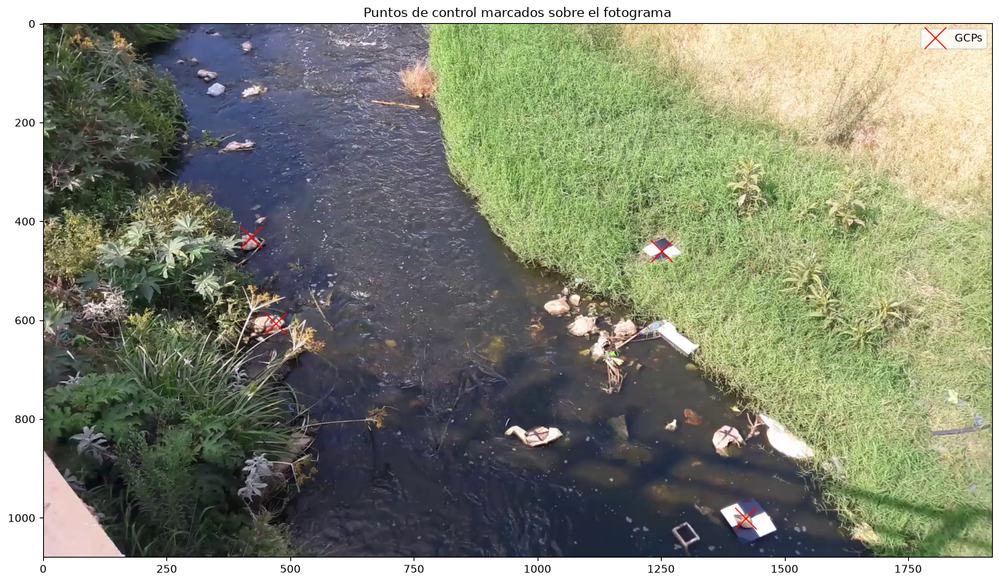

In [3]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Puntos de control (obtenidos del dataset)
# ---------------------------------------------------------------------------------------
gcps = dict(
    # Coordenadas en pixeles [columna, fila] de los cuatro marcadores.
    src=[
        [1421, 1001],
        [1251, 460],
        [421, 432],
        [470, 607],
    ],
    # Las mismas coordenadas en UTM 35S [este, norte]. El ORDEN debe coincidir con src.
    dst=[
        [642735.8076, 8304292.119],
        [642737.5823, 8304295.593],
        [642732.7864, 8304298.425],
        [642732.6705, 8304296.858],
    ],
    h_ref=0.0,   # nivel local de referencia durante el video (0 al procesar un solo video)
    z_0=1182.2,  # cota absoluta del agua en metros; se usa luego para calcular profundidades
)
# ---------------------------------------------------------------------------------------

plt.figure(figsize=(16, 9))
plt.imshow(frame)
# zip(*gcps["src"]) separa la lista de pares en dos secuencias (columnas, filas);
# el * delante las pasa a plot como los argumentos x e y.
plt.plot(*zip(*gcps["src"]), "rx", markersize=20, label="GCPs")
plt.legend()
plt.title("Puntos de control marcados sobre el fotograma")
plt.savefig(DIR_SALIDA / "fig2_puntos_control.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 3 - Configuracion de camara y reproyeccion

`CameraConfig` resuelve la transformacion entre pixeles y metros a partir de los GCPs. Ademas hay
que decirle:

- el area de interes (AOI), con cuatro esquinas en pixeles; pyorc encaja un rectangulo
  georreferenciado alrededor
- la resolucion de salida en metros por pixel
- el tamano de la ventana de interrogacion del PIV, en pixeles de la imagen reproyectada

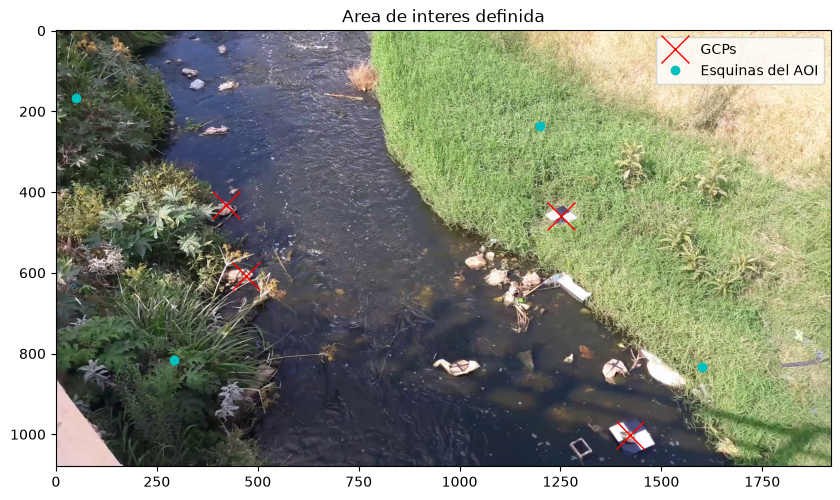

Configuracion guardada en: salidas\cam_config.json


In [4]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Malla de reproyeccion y area de interes
# ---------------------------------------------------------------------------------------
# Resolucion de la imagen ortorrectificada: 0.01 m/pixel = 1 cm por pixel.
RESOLUCION = 0.01             # m/px
# Ventana de interrogacion del PIV: 25 pixeles = 25 cm de lado con la resolucion anterior.
VENTANA_PIV = 25              # px
# Cuatro esquinas del area de interes, en pixeles [columna, fila].
# No hace falta que formen un rectangulo: pyorc ajusta uno en coordenadas reales.
ESQUINAS_AOI = [
    [292, 817],
    [50, 166],
    [1200, 236],
    [1600, 834],
]
# ---------------------------------------------------------------------------------------

# height y width se toman del propio fotograma para no escribirlos a mano.
cam_config = pyorc.CameraConfig(
    height=frame.shape[0],   # 1080 filas
    width=frame.shape[1],    # 1920 columnas
    gcps=gcps,               # los puntos de control definidos arriba
    crs=32735,               # EPSG:32735 = UTM zona 35S, la zona de Lusaka (Zambia)
)
cam_config.set_bbox_from_corners(ESQUINAS_AOI)
cam_config.resolution = RESOLUCION
cam_config.window_size = VENTANA_PIV

plt.figure(figsize=(10, 6))
plt.imshow(frame)
plt.plot(*zip(*gcps["src"]), "rx", markersize=20, label="GCPs")
plt.plot(*zip(*ESQUINAS_AOI), "co", label="Esquinas del AOI")
plt.legend()
plt.title("Area de interes definida")
plt.savefig(DIR_SALIDA / "fig3_area_interes.png", dpi=110, bbox_inches="tight")
plt.show()

# Se guarda en JSON dentro de salidas/.
cam_config.to_file(str(SALIDA_CAM_CONFIG))
print(f"Configuracion guardada en: {SALIDA_CAM_CONFIG}")

Scanning video:   0%|          | 0/2 [00:00<?, ?it/s]

Scanning video:  50%|█████     | 1/2 [00:00<00:00,  5.82it/s]

Scanning video: 100%|██████████| 2/2 [00:00<00:00,  5.57it/s]

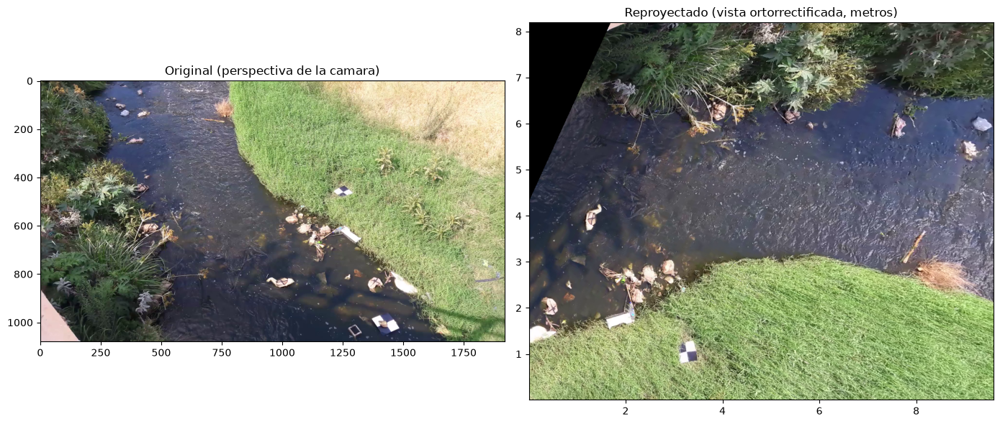

In [5]:
# Comprobacion visual de que la reproyeccion funciona, con un solo fotograma.
video_demo = pyorc.Video(
    str(ARCHIVO_VIDEO),
    camera_config=cam_config,  # al pasar la config, los frames ya saben reproyectarse
    start_frame=0,
    end_frame=1,
    h_a=0.0,                   # nivel del agua de ESTE video respecto a h_ref (mismo video: 0)
)

# get_frames devuelve un xarray.DataArray perezoso (dask); nada se calcula todavia.
da_rgb_demo = video_demo.get_frames(method="rgb")

# .frames es el accesor que pyorc registra en xarray; project ortorrectifica a la malla del AOI.
da_rgb_proj_demo = da_rgb_demo.frames.project()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(frame)
axes[0].set_title("Original (perspectiva de la camara)")
# Aqui si se fuerza el calculo, porque hay que dibujar los pixeles.
da_rgb_proj_demo[0].frames.plot(ax=axes[1])
axes[1].set_title("Reproyectado (vista ortorrectificada, metros)")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig4_reproyeccion.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4 - Velocidades superficiales con LSPIV

Ahora se procesa el video completo. La cadena es: estabilizar, pasar a gris, normalizar,
reproyectar y correlacionar pares de fotogramas consecutivos.

`normalize` resta la media de un conjunto de fotogramas, de modo que solo quedan los patrones que
se mueven respecto al fondo: son los trazadores que el PIV puede seguir.

In [6]:
from dask.diagnostics import ProgressBar

# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Cuanto video se procesa y que zona se considera fija
# ---------------------------------------------------------------------------------------
# 126 fotogramas a 30 fps = unos 4.2 s, suficiente para este caso.
N_FRAMES = 125
# Poligono en pixeles que envuelve la superficie del agua. Todo lo que queda FUERA se
# considera terreno inmovil: cualquier movimiento detectado ahi es temblor de la camara, y
# pyorc lo usa para corregir el resto de la imagen.
POLIGONO_ESTABILIZAR = [
    [150, 0],
    [500, 1079],
    [1750, 1079],
    [900, 0],
]
# ---------------------------------------------------------------------------------------

# Se recarga la configuracion desde el JSON recien escrito. Es la prueba de que el archivo
# guardado es completo y de que a partir de aqui no depende nada de las celdas anteriores.
cam_config = pyorc.load_camera_config(str(SALIDA_CAM_CONFIG))

video = pyorc.Video(
    str(ARCHIVO_VIDEO),
    camera_config=cam_config,
    start_frame=0,
    end_frame=N_FRAMES,
    stabilize=POLIGONO_ESTABILIZAR,  # activa la correccion de temblor
    h_a=0.0,                         # nivel del agua igual al de la medicion de los GCPs
)

# Sin method="rgb" los fotogramas salen en escala de grises, que es lo que necesita el PIV.
da = video.get_frames()

# Resta el fondo (media de varios fotogramas) para realzar los trazadores en movimiento.
da_norm = da.frames.normalize()

# Ortorrectifica cada fotograma a la malla del AOI. method="numpy" es la implementacion
# vectorizada; sin ese argumento se usa la de OpenCV.
da_norm_proj = da_norm.frames.project(method="numpy")

print("Calculando velocidades (PIV)...")
with ProgressBar():
    piv = da_norm_proj.frames.get_piv()

# to_netcdf escribe el resultado a disco.
piv.to_netcdf(SALIDA_PIV_CRUDO)
print(f"Velocimetria cruda guardada en: {SALIDA_PIV_CRUDO}")

Scanning video:   0%|          | 0/126 [00:00<?, ?it/s]

Scanning video:   1%|          | 1/126 [00:00<00:17,  7.18it/s]

Scanning video:   6%|▌         | 7/126 [00:00<00:03, 32.91it/s]

Scanning video:   9%|▊         | 11/126 [00:00<00:03, 35.55it/s]

Scanning video:  15%|█▌        | 19/126 [00:00<00:02, 51.39it/s]

...

[####################################### ] | 98% Completed | 18.03 s

[########################################] | 100% Completed | 18.21 s

Computing PIV per chunk: 100%|██████████| 1/1 [00:45<00:00, 45.25s/it]

Computing PIV per chunk: 100%|██████████| 1/1 [00:45<00:00, 45.25s/it]

Velocimetria cruda guardada en: salidas\piv_crudo.nc


Dimensiones del resultado PIV: {'time': 125, 'y': 57, 'x': 67}


Scanning video:   0%|          | 0/2 [00:00<?, ?it/s]

Scanning video:  50%|█████     | 1/2 [00:00<00:00,  6.97it/s]

Scanning video: 100%|██████████| 2/2 [00:00<00:00,  5.81it/s]

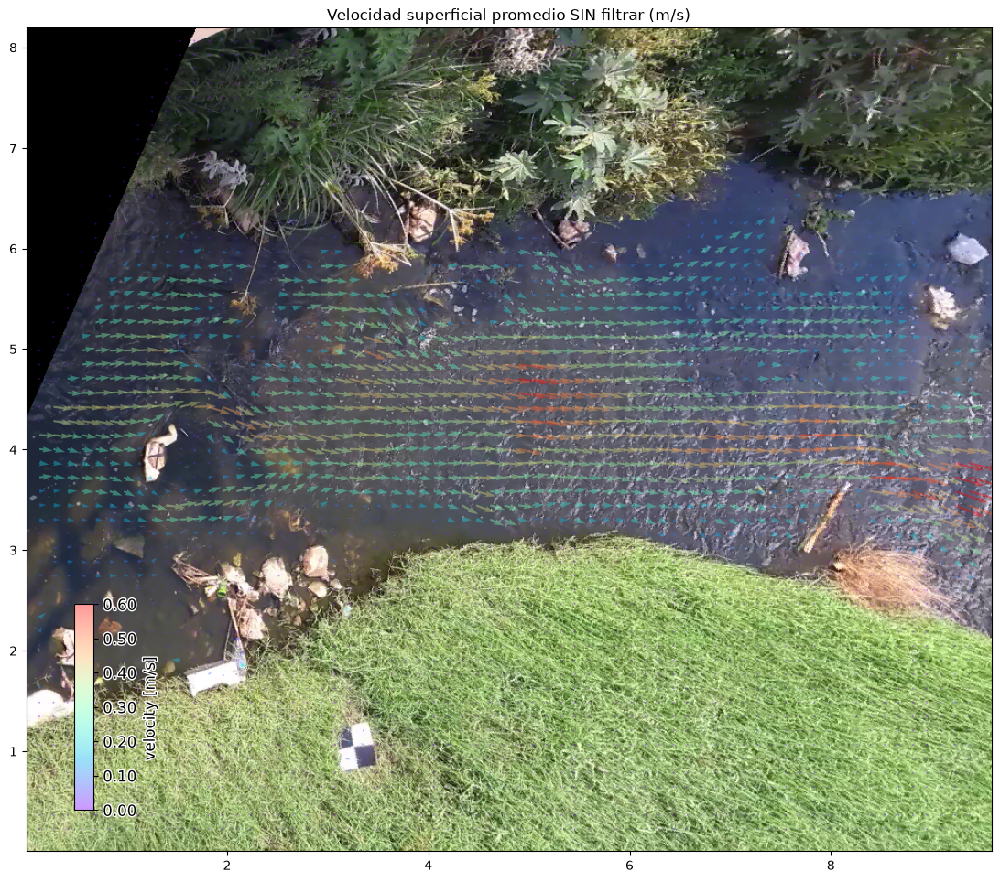

In [7]:
import xarray as xr
from matplotlib.colors import Normalize

# Se relee desde el NetCDF: el dataset trae v_x, v_y, s2n y corr, mas la config de camara
# embebida en los atributos.
ds = xr.open_dataset(SALIDA_PIV_CRUDO)
print(f"Dimensiones del resultado PIV: {dict(ds.sizes)}")

# Se reabre el video sin estabilizar para tener un fotograma en color como fondo.
video_rgb = pyorc.Video(str(ARCHIVO_VIDEO), start_frame=0, end_frame=1)
# La config de camara se recupera del propio dataset, no hay que volver a construirla.
video_rgb.camera_config = ds.velocimetry.camera_config
da_rgb = video_rgb.get_frames(method="rgb")
da_rgb_proj = da_rgb.frames.project()

# No se pueden dibujar tres dimensiones a la vez, asi que se promedia en el tiempo.
# keep_attrs=True conserva la config de camara y los metadatos, que hacen falta para plotear.
ds_mean = ds.mean(dim="time", keep_attrs=True)

# Escala de color fija de 0 a 0.6 m/s.
NORMA_COLOR = Normalize(vmin=0.0, vmax=0.6, clip=False)

p = da_rgb_proj[0].frames.plot()          # fondo ortorrectificado en color
ds_mean.velocimetry.plot(ax=p.axes, alpha=0.4, norm=NORMA_COLOR, add_colorbar=True)
plt.title("Velocidad superficial promedio SIN filtrar (m/s)")
plt.savefig(DIR_SALIDA / "fig5_velocidades_sin_filtrar.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4b - Filtrado de velocidades espurias

Paso imprescindible. El PIV devuelve un vector por cada ventana de interrogacion, incluidas la
tierra firme, las rocas y las zonas sin trazadores visibles, donde la correlacion es practicamente
ruido. Esos vectores apuntan en direcciones aleatorias y al promediarlos cancelan parte del flujo
real: el caudal sale subestimado y algunos cuantiles pueden salir negativos, lo cual es
fisicamente imposible.

El orden de las mascaras importa cuando se aplican con `inplace=True`, porque cada una condiciona a
la siguiente. El orden recomendado, y el del ejemplo original, es:

1. las que juzgan valores individuales: `corr`, `minmax`
2. las temporales: `rolling`, `outliers`, `variance`
3. las que necesitan la serie completa o la vecindad espacial: `count`, `window_mean`

Vectores validos antes del filtrado: 462149
Vectores validos despues:            108214 (23.4 %)


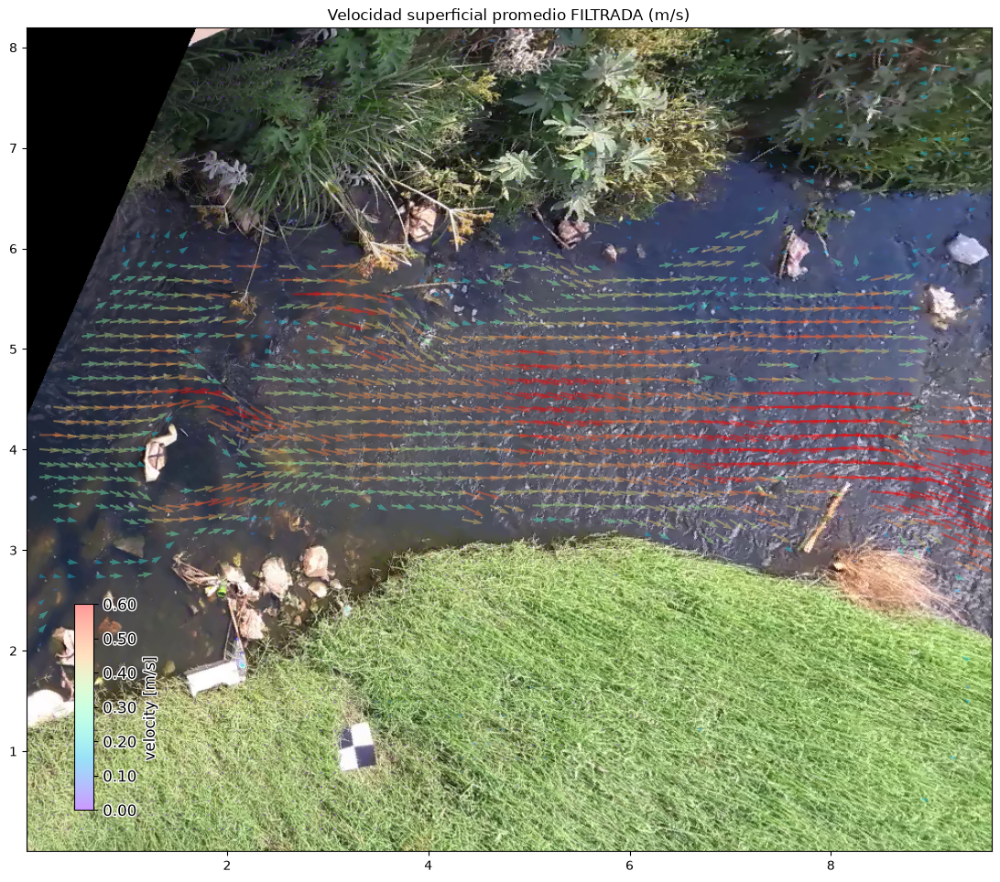

Velocimetria filtrada guardada en: salidas\piv_filtrado.nc


In [8]:
import copy

import numpy as np

# deepcopy para conservar intacto el dataset crudo y poder comparar despues.
ds_mask = copy.deepcopy(ds)

# --- 1) mascaras sobre valores individuales ---
# corr: descarta ventanas cuya correlacion maxima es demasiado baja (no habia patron que seguir).
ds_mask.velocimetry.mask.corr(inplace=True)
# minmax: descarta velocidades fuera de un rango plausible.
ds_mask.velocimetry.mask.minmax(inplace=True)

# --- 2) mascaras en el dominio del tiempo ---
# rolling: compara cada valor con una media movil temporal de su propia celda.
ds_mask.velocimetry.mask.rolling(inplace=True)
# outliers: descarta valores que se apartan demasiado de la media temporal de la celda.
ds_mask.velocimetry.mask.outliers(inplace=True)
# variance: descarta celdas cuya velocidad varia de forma inverosimil a lo largo del tiempo.
ds_mask.velocimetry.mask.variance(inplace=True)

# angle: descartaria los vectores cuya direccion se aparta del flujo esperado (izquierda a
# derecha por defecto). Con angle_tolerance=0.5*pi la tolerancia es de 90 grados, holgada
# porque el agua rodea rocas y cambia de direccion.
# ATENCION: el ejemplo original (03_Plotting_and_masking_velocimetry_results) llama a esta
# mascara SIN inplace=True, a diferencia de todas las demas, asi que la calcula y la descarta:
# nunca se aplica al dataset que luego guarda. Se replica aqui ese mismo comportamiento para
# reproducir el caudal publicado de 0.164 m3/s.
mask_angle = ds_mask.velocimetry.mask.angle(angle_tolerance=0.5 * np.pi)

# --- 3) mascaras que necesitan toda la serie o la vecindad espacial ---
# count: elimina las celdas que, tras los filtros anteriores, se quedaron con muy pocos valores
# validos respecto al total de pasos de tiempo.
ds_mask.velocimetry.mask.count(inplace=True)
# window_mean: compara cada celda con la media de su entorno de 5x5 (wdw=2) sobre el promedio
# temporal (reduce_time=True) y la descarta si se desvia mas de un 50 % (tolerance=0.5).
ds_mask.velocimetry.mask.window_mean(wdw=2, inplace=True, tolerance=0.5, reduce_time=True)

# Promedio temporal del campo ya filtrado, para dibujar y para el mapa final.
ds_mean_mask = ds_mask.mean(dim="time", keep_attrs=True)

# count() sobre un DataArray cuenta solo los valores no nulos: sirve para medir cuanto se filtro.
n_antes = int(ds["v_x"].count())
n_despues = int(ds_mask["v_x"].count())
print(f"Vectores validos antes del filtrado: {n_antes}")
print(f"Vectores validos despues:            {n_despues} ({100 * n_despues / n_antes:.1f} %)")

p = da_rgb_proj[0].frames.plot()
ds_mean_mask.velocimetry.plot(ax=p.axes, alpha=0.4, norm=NORMA_COLOR, add_colorbar=True)
plt.title("Velocidad superficial promedio FILTRADA (m/s)")
plt.savefig(DIR_SALIDA / "fig6_velocidades_filtradas.png", dpi=110, bbox_inches="tight")
plt.show()

# Se guarda el campo filtrado sin set_encoding(), para que el archivo contenga exactamente los
# mismos valores en coma flotante que usan las celdas siguientes.
ds_mask.to_netcdf(SALIDA_PIV_FILTRADO)
print(f"Velocimetria filtrada guardada en: {SALIDA_PIV_FILTRADO}")

---
## Parte 5 - Caudal sobre el transecto

Para llegar al caudal hacen falta cuatro pasos:

1. leer la batimetria del transecto (CSV con `x`, `y`, `z` en UTM 35S y en la misma referencia
   vertical que `z_0`)
2. muestrear las velocidades **filtradas** en esos puntos, con `get_transect`
3. rellenar los huecos con un perfil logaritmico y pasar de velocidad superficial a velocidad
   media en la vertical, con `get_q`
4. integrar a lo ancho de la seccion, con `get_river_flow`

`v_corr` es el cociente entre la velocidad media en la vertical y la superficial: el unico
parametro del calculo que no se puede medir en la imagen. Se usa el valor por defecto de pyorc,
0.9, el mismo que el ejemplo original.

In [9]:
import pandas as pd

# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Paso de velocidad superficial a media en la vertical
# ---------------------------------------------------------------------------------------
V_CORR = 0.9                  # valor por defecto de pyorc, el del ejemplo original
# ---------------------------------------------------------------------------------------

# El CSV trae tres columnas: x (este UTM), y (norte UTM), z (cota del lecho en metros).
cross_section = pd.read_csv(ARCHIVO_BATIMETRIA)
print(f"Puntos batimetricos medidos: {len(cross_section)}")

# El muestreo se hace sobre ds_mask (filtrado), NO sobre ds (crudo): es el punto donde el
# filtrado se traduce en el caudal.
transect = ds_mask.velocimetry.get_transect(
    cross_section["x"],
    cross_section["y"],
    cross_section["z"],
    crs=32735,   # el CSV esta en UTM 35S; conviene declararlo aunque coincida con el del dataset
    rolling=4,   # media movil de 4 pasos de tiempo antes de calcular los cuantiles
    # wdw=1 (por defecto) toma la mediana de una ventana de 3x3 celdas alrededor de cada punto.
)

# Los puntos batimetricos se remuestrean a la resolucion de la malla de velocidades, de modo que
# el numero de puntos del transecto no coincide con el del CSV.
print(f"Puntos del transecto tras remuestrear: {transect.sizes['points']}")
print(f"Cuantiles calculados: {transect['quantile'].values}")

# get_q convierte velocidad superficial en caudal por unidad de ancho. Los huecos sin velocidad
# valida se rellenan ajustando un perfil logaritmico ("log_interp"); con "zeros" valdrian 0 m/s
# y el caudal quedaria subestimado.
q_transect = transect.transect.get_q(v_corr=V_CORR, fill_method="log_interp")
# get_river_flow integra q a lo ancho de la seccion y anade river_flow al dataset.
q_transect.transect.get_river_flow()

Puntos batimetricos medidos: 27


Puntos del transecto tras remuestrear: 36
Cuantiles calculados: [0.05 0.25 0.5  0.75 0.95]


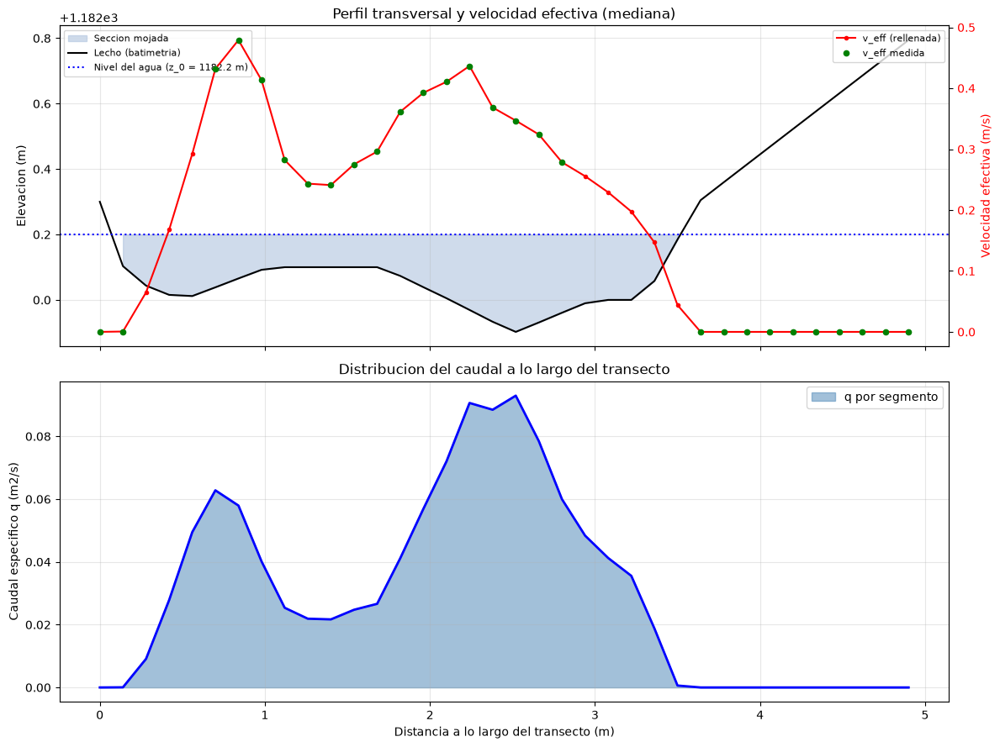

In [10]:
# quantile=0.5 es la mediana.
q_med = q_transect.sel(quantile=0.5)

# scoords es la distancia acumulada a lo largo del transecto, en metros desde una orilla.
s = q_med["scoords"].values
# La cota del agua se lee de la propia config de camara, para no repetir el numero a mano.
z_0 = ds_mask.velocimetry.camera_config.gcps["z_0"]

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

# --- Panel superior: geometria de la seccion y velocidad efectiva ---
ax_z = axes[0]
# Relleno entre el lecho y la superficie del agua, solo donde el lecho queda por debajo.
ax_z.fill_between(s, q_med["zcoords"].values, z_0,
                  where=q_med["zcoords"].values < z_0,
                  color="lightsteelblue", alpha=0.6, label="Seccion mojada")
ax_z.plot(s, q_med["zcoords"].values, "k-", lw=1.5, label="Lecho (batimetria)")
ax_z.axhline(z_0, color="b", ls=":", lw=1.5, label=f"Nivel del agua (z_0 = {z_0} m)")
ax_z.set_ylabel("Elevacion (m)")
ax_z.set_title("Perfil transversal y velocidad efectiva (mediana)")
ax_z.legend(loc="upper left", fontsize=8)
ax_z.grid(True, alpha=0.3)

# twinx crea un segundo eje y que comparte el eje x, para superponer velocidades a las cotas.
ax_v = ax_z.twinx()
# v_eff: velocidad perpendicular al transecto, ya con los huecos rellenados.
ax_v.plot(s, q_med["v_eff"].values, "r-o", ms=3, lw=1.5, label="v_eff (rellenada)")
# v_eff_nofill: solo los puntos donde realmente hubo medida valida. Los huecos delatan cuanta
# parte del perfil es interpolacion.
ax_v.plot(s, q_med["v_eff_nofill"].values, "g.", ms=9, label="v_eff medida")
ax_v.set_ylabel("Velocidad efectiva (m/s)", color="r")
ax_v.tick_params(axis="y", labelcolor="r")
ax_v.legend(loc="upper right", fontsize=8)

# --- Panel inferior: caudal especifico ---
# q es el caudal por segmento en m2/s: velocidad media en la vertical por profundidad.
axes[1].fill_between(s, q_med["q"].values, alpha=0.5, color="steelblue", label="q por segmento")
axes[1].plot(s, q_med["q"].values, "b-", lw=2)
axes[1].set_xlabel("Distancia a lo largo del transecto (m)")
axes[1].set_ylabel("Caudal especifico q (m2/s)")
axes[1].set_title("Distribucion del caudal a lo largo del transecto")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig7_perfil_transecto.png", dpi=110, bbox_inches="tight")
plt.show()

In [11]:
caudal = q_transect["river_flow"]

# Valores publicados por el ejemplo original, notebook
# 04_Extracting_crosssection_velocities_and_discharge, seccion transversal #1.
referencia = [0.07647424, 0.12637030, 0.16405959, 0.19231923, 0.22172388]

print("=" * 62)
print("CAUDAL POR CUANTIL (m3/s)")
print("=" * 62)
print(f"{'cuantil':>8} {'este notebook':>15} {'ejemplo original':>18} {'dif.':>10}")
# zip recorre en paralelo los cuantiles calculados y los valores de referencia.
for qt, ref in zip(caudal["quantile"].values, referencia):
    val = float(caudal.sel(quantile=qt))
    print(f"{qt:>8.2f} {val:>15.4f} {ref:>18.4f} {val - ref:>+10.4f}")

Q_VIDEO = float(caudal.sel(quantile=0.50))   # estimacion central
q_05 = float(caudal.sel(quantile=0.05))      # limite inferior de la banda de incertidumbre
q_95 = float(caudal.sel(quantile=0.95))      # limite superior

print("\n" + "-" * 62)
print(f"Caudal (mediana): {Q_VIDEO:.4f} m3/s   "
      f"[esperado {referencia[2]:.4f} m3/s, dif. {100 * (Q_VIDEO / referencia[2] - 1):+.1f} %]")
print(f"Incertidumbre:    P5 = {q_05:.4f} m3/s   P95 = {q_95:.4f} m3/s")
print("-" * 62)

# Tabla final en CSV, comoda para comparar entre ejecuciones.
resumen = pd.DataFrame({
    "cuantil": caudal["quantile"].values,
    "caudal_m3s": caudal.values,
    "referencia_ejemplo_m3s": referencia,
})
resumen["diferencia_m3s"] = resumen["caudal_m3s"] - resumen["referencia_ejemplo_m3s"]
resumen.to_csv(SALIDA_RESUMEN, index=False)

# El transecto completo se guarda tambien en NetCDF: contiene v_eff, q, river_flow y todas las
# coordenadas del muestreo, por si se quiere reanalizar sin repetir el PIV.
q_transect.to_netcdf(SALIDA_TRANSECTO)
print(f"\nResumen guardado en:   {SALIDA_RESUMEN}")
print(f"Transecto guardado en: {SALIDA_TRANSECTO}")
resumen

CAUDAL POR CUANTIL (m3/s)
 cuantil   este notebook   ejemplo original       dif.
    0.05          0.0543             0.0765    -0.0222
    0.25          0.1101             0.1264    -0.0163
    0.50          0.1530             0.1641    -0.0111
    0.75          0.1928             0.1923    +0.0004
    0.95          0.2478             0.2217    +0.0261

--------------------------------------------------------------
Caudal (mediana): 0.1530 m3/s   [esperado 0.1641 m3/s, dif. -6.7 %]
Incertidumbre:    P5 = 0.0543 m3/s   P95 = 0.2478 m3/s
--------------------------------------------------------------

Resumen guardado en:   salidas\caudal_resumen.csv
Transecto guardado en: salidas\transecto_caudal.nc


,cuantil,caudal_m3s,referencia_ejemplo_m3s,diferencia_m3s
0,0.05,0.054266,0.076474,-0.022208
1,0.25,0.110117,0.126370,-0.016253
2,0.50,0.153005,0.164060,-0.011055
3,0.75,0.192759,0.192319,0.000440
4,0.95,0.247819,0.221724,0.026095


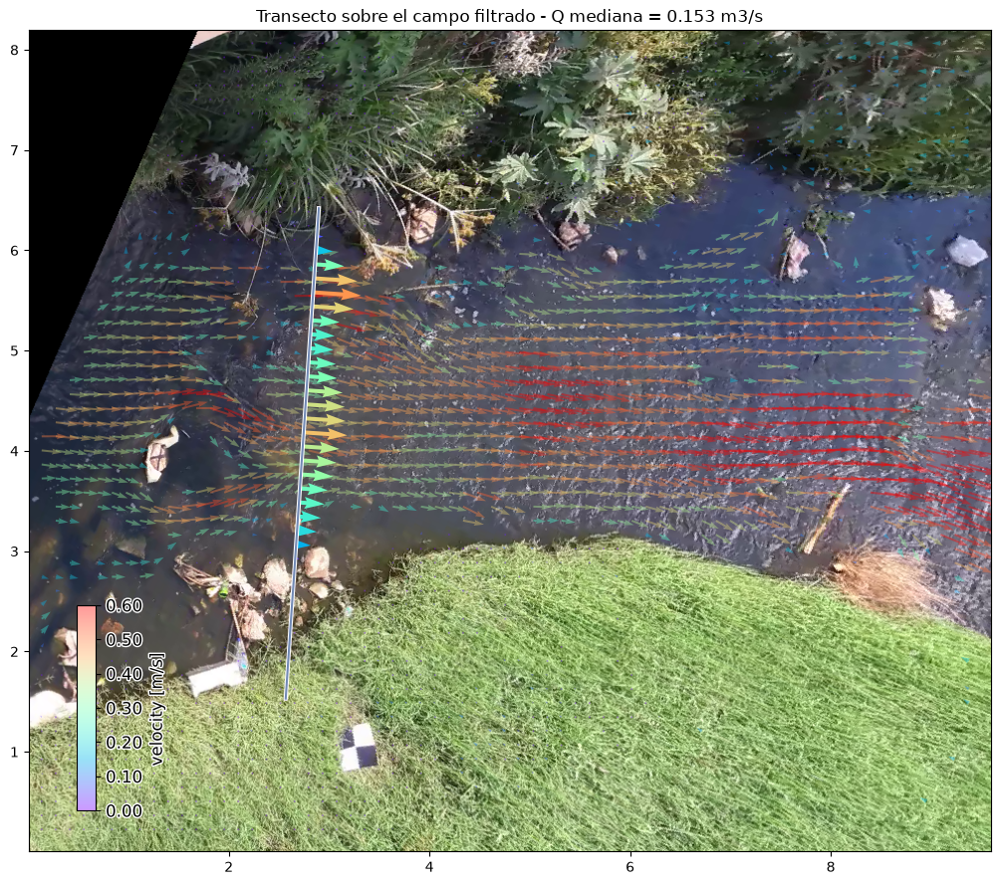

In [12]:
# Mapa final: transecto sobre el campo de velocidades filtrado.
# El fondo se dibuja en proyeccion "local" (metros desde la esquina del AOI), asi que NO se
# pueden pasar las coordenadas UTM del CSV directamente a ax.plot(): caerian fuera del grafico.
# Se usa .transect.plot(), que ya conoce las coordenadas locales de cada punto muestreado.
p = da_rgb_proj[0].frames.plot(mode="local")  # fotograma ortorrectificado como fondo
ds_mean_mask.velocimetry.plot(ax=p.axes, mode="local", alpha=0.4, norm=NORMA_COLOR,
                              add_colorbar=True)
q_transect.sel(quantile=0.5).transect.plot(ax=p.axes, mode="local", cmap="rainbow",
                                           norm=NORMA_COLOR, width=2)
p.axes.set_title(f"Transecto sobre el campo filtrado - Q mediana = {Q_VIDEO:.3f} m3/s")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig8_mapa_transecto.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Archivos generados

Todo queda en `salidas/`, sin tocar nada de `../../datos/ngwerere/`.

In [13]:
print(f"Contenido de {DIR_SALIDA}:\n")
for archivo in sorted(DIR_SALIDA.iterdir()):
    # st_size da el tamano en bytes; se divide entre 1024 para mostrarlo en KiB.
    print(f"  {archivo.name:<34} {archivo.stat().st_size / 1024:>10.1f} KiB")

Contenido de salidas:

  cam_config.json                           3.5 KiB
  caudal_resumen.csv                        0.3 KiB
  fig1_fotograma.png                      800.9 KiB
  fig2_puntos_control.png                1796.4 KiB
  fig3_area_interes.png                   799.2 KiB
  fig4_reproyeccion.png                  1351.6 KiB
  fig5_velocidades_sin_filtrar.png       1944.2 KiB
  fig6_velocidades_filtradas.png         1934.1 KiB
  fig7_perfil_transecto.png               114.0 KiB
  fig8_mapa_transecto.png                1697.7 KiB
  piv_crudo.nc                           1999.9 KiB
  piv_filtrado.nc                       15119.4 KiB
  transecto_caudal.nc                      45.1 KiB


---
## Lectura del resultado

### Por que la mediana no coincide al decimal, y cuanto cambia de una ejecucion a otra

El caudal **no se repite exactamente entre ejecuciones** del mismo notebook sin tocar nada. Medido:

| ejecucion | caudal (mediana) | frente a 0.164 publicado |
|---|---|---|
| `casos/01_ngwerere_pyorc` | 0.1672 m3/s | +1.9 % |
| esta carpeta, primera | 0.1530 m3/s | -6.7 % |
| esta carpeta, segunda (copia aparte) | 0.1644 m3/s | +0.2 % |

El valor de esta pagina es el de la ejecucion guardada. El campo medio de velocidades si se repite
(v_x media 0.0850 frente a 0.0849 m/s entre ejecuciones), pero cada vector cambia unos 2 cm/s; la
estabilizacion y la focal, que pyorc estima con solo cuatro puntos de control (1429 px frente a los
1552 del `ngwerere.json` del repositorio), no son reproducibles bit a bit. Las mascaras de la Parte
4b son umbrales: un vector que cae a un lado u otro cambia que celdas sobreviven, y con ellas los
cuantiles del transecto. La dispersion entre ejecuciones (~7 %) es del orden de la banda P25-P75, y
mayor que el 1-2 % que se suponia.

Aparte, la malla de velocidades sale a 0.14 m de paso en vez de los 0.13 m del ejemplo: la version
actual de ffpiv redondea `window_size` al par superior (25 pasa a 26) y usa `overlap = 12`.

### Limitaciones conocidas

1. **La referencia no es independiente.** 0.164 m3/s es el resultado publicado del mismo flujo de
   pyorc, no un aforo: el notebook comprueba que se reproduce el ejemplo, no que el caudal sea el
   real del rio.
2. **`v_corr` no se puede medir en la imagen.** Se usa el 0.9 por defecto.
3. **El resultado no es reproducible bit a bit.** Con solo cuatro puntos la focal la estima pyorc,
   y la estabilizacion tampoco se repite exactamente: el caudal se ha movido un ~7 % entre
   ejecuciones identicas.
4. **Solo 4.2 s de video.** Suficiente para reproducir el ejemplo; la banda P5-P95 lo refleja.